# Tutorial de biplotpy 0.4.0

biplotpy reúne en Python los biplots de la escuela de Salamanca y de otros
paquetes de R (MultBiplotR, GGEBiplots, smacof, vegan, ade4, FactoMineR, heplots...),
validados numéricamente contra R. Este tutorial muestra un ejemplo de cada familia de
métodos, con datos incluidos en el paquete o simulados aquí mismo.

Familias:
1. Biplots clásicos (GH, JK, HJ)
2. Biplot canónico, MANOVA y gráficos HE
3. Biplots logísticos (binario, ordinal, nominal, restringidos y externos)
4. Tablas múltiples: STATIS y biplot dinámico
5. Interacción genotipo × ambiente: GGE y AMMI
6. Correspondencias: CA, MCA, CCA y RDA
7. Distancias: coordenadas principales, MDS y su bootstrap
8. Modelos factoriales y PLS (incluida la PLS con respuestas binarias)
9. Otros: unfolding, DISTATIS, CDPCA y biplot de frecuencias logarítmicas

Instalación: `pip install biplotpy-0.4.0-py3-none-any.whl`.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import biplotpy as bp
print(bp.__version__)
iris = bp.load_iris()
X, especie = iris.iloc[:, :4], iris["Species"]
rng = np.random.default_rng(2026)

0.4.0


## 1. Biplots clásicos

El HJ-Biplot (Galindo, 1986) representa filas y columnas con la misma calidad. `summary()`
devuelve autovalores, contribuciones y calidades de representación; `plot()` admite elipses,
envolturas convexas o *alpha-bags* por grupo y ejes calibrados.

       Eigenvalue   Exp. Var  Cumulative
Dim 1  434.856175  72.962445   72.962445
Dim 2  136.190540  22.850762   95.813207
              Dim 1  Dim 2
Sepal.Length   79.2   92.3
Sepal.Width    21.2   99.1
Petal.Length   98.3   98.4
Petal.Width    93.1   93.5


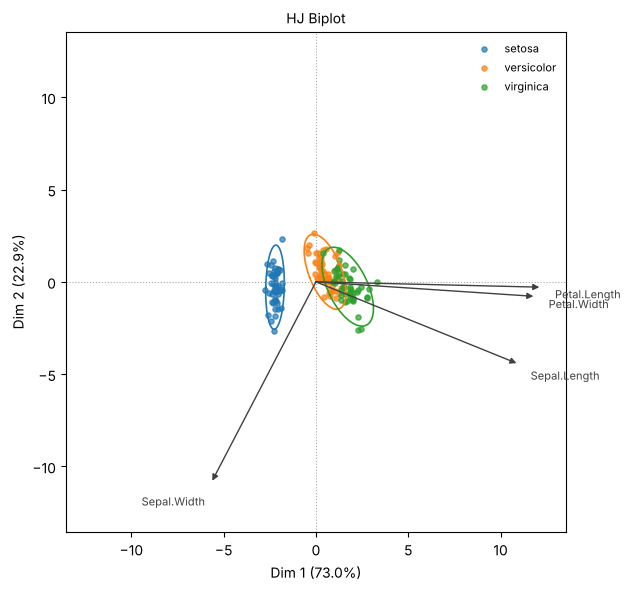

In [2]:
hj = bp.hj_biplot(X, dim=2)
print(hj.summary()["eigen"])
print(hj.summary()["col_qualities"].round(1))
hj.plot(groups=especie, group_shape="ellipse"); plt.show()

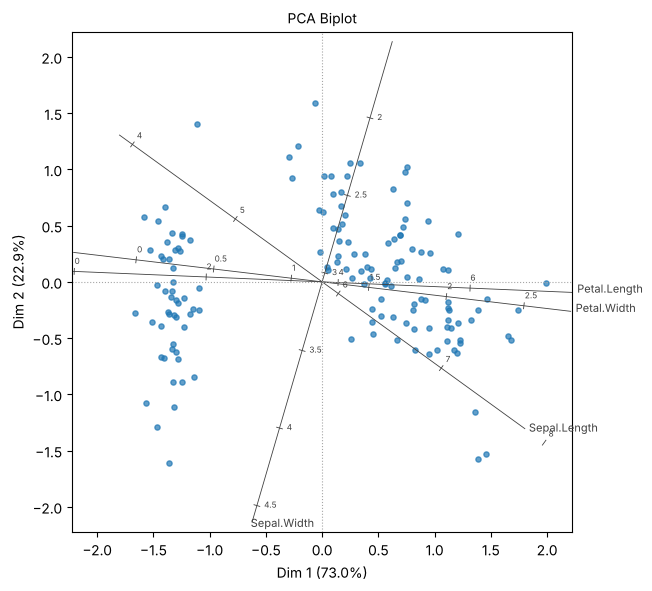

In [3]:
jk = bp.jk_biplot(X)
bp.plot_biplot(jk, calibrated=True, show_rows=True); plt.show()   # ejes calibrados (predictivos)

## 2. Biplot canónico, MANOVA y gráficos HE

El biplot canónico (MANOVA biplot) separa los grupos al máximo e incluye las pruebas MANOVA y
círculos de confianza para las medias. El gráfico HE (heplots) compara la matriz de hipótesis
con la de error; con varios factores, `he_plot_terms` dibuja una elipse por término (tipos II o III,
como `car::Anova`).

                  Statistic            F  df1    df2              p
Wilks              0.023439   199.145344  8.0  288.0  1.365006e-112
Pillai             1.191899    53.466489  8.0  290.0   9.742163e-53
Hotelling-Lawley  32.477320   580.532099  8.0  286.0  6.436176e-172
Roy               32.191929  1166.957433  4.0  145.0  3.787298e-109


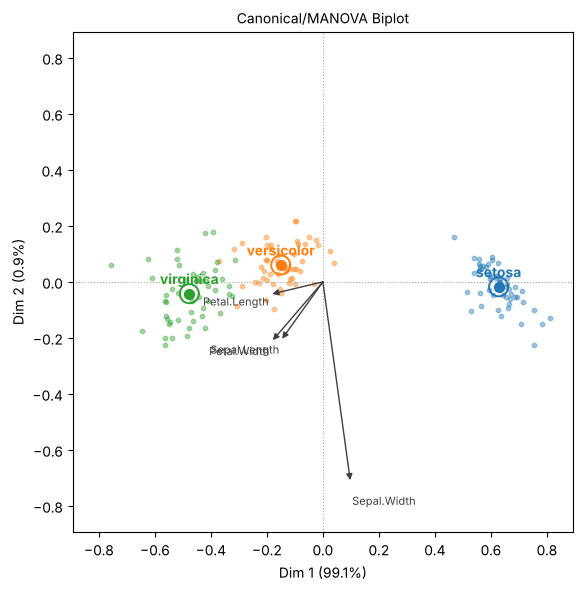

In [4]:
cb = bp.canonical_biplot(X, especie)
print(cb.manova)
cb.plot(radius="bonferroni"); plt.show()

{'A': np.float64(0.546), 'B': np.float64(0.169), 'A:B': np.float64(0.058)}


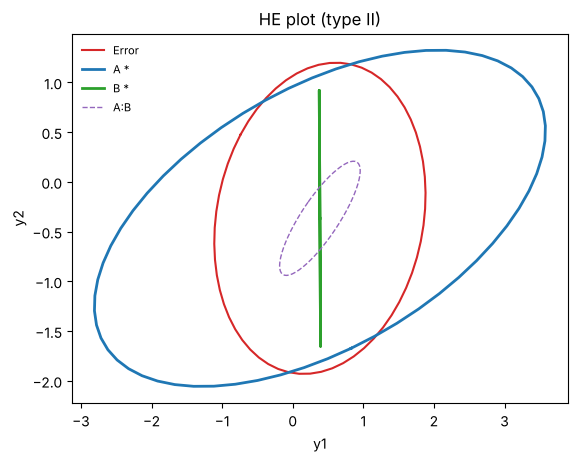

In [5]:
# MANOVA de dos factores (desbalanceado)
n = 60
A = rng.choice(["a1", "a2", "a3"], n); B = rng.choice(["b1", "b2"], n)
Y = rng.normal(size=(n, 3)) + np.column_stack([(A == "a2") * 1.0, -0.8 * (A == "a3"), (B == "b2") * 0.6])
m = bp.manova_terms(Y, pd.DataFrame({"A": A, "B": B}), ["A", "B", "A:B"], type="II")
print({t: round(r["stats"]["Pillai"], 3) for t, r in m["terms"].items()})
bp.he_plot_terms(Y, pd.DataFrame({"A": A, "B": B}), labels=("y1", "y2")); plt.show()

In [6]:
# MANOVA heterocedástica (WTS/MATS con bootstrap paramétrico, MANOVA.RM)
r = bp.manova_wts(X.to_numpy(), especie, iter=999, seed=1)
print("WTS:", np.round(r["WTS"], 3), " MATS:", np.round(r["MATS"], 3))

WTS: 6142.293  MATS: 6631.68


## 3. Biplots logísticos

Para datos binarios, ordinales o nominales. Los **restringidos** construyen las coordenadas de
las filas como combinaciones lineales de variables explicativas continuas; el biplot **externo**
ajusta las variables sobre una configuración dada (PCA, PCoA, MDS).

Binary Logistic Biplot: 80 rows, 6 variables, dim = 2, penalization = 0.5
Objective = 174.5112; global % correct = 89.17
       b0     b1     b2  Deviance  p-value  % correct  McFadden R2
V1  0.139 -1.472 -3.126    60.123      0.0      82.50        0.542
V2  0.284 -2.621 -2.019    60.055      0.0      86.25        0.544
V3  0.148  1.376 -2.924    54.720      0.0      86.25        0.494
V4 -0.356  3.442 -2.273    74.844      0.0      93.75        0.676
V5  0.563 -2.672  2.543    65.508      0.0      88.75        0.597
V6  0.129 -3.891 -2.248    83.240      0.0      97.50        0.751


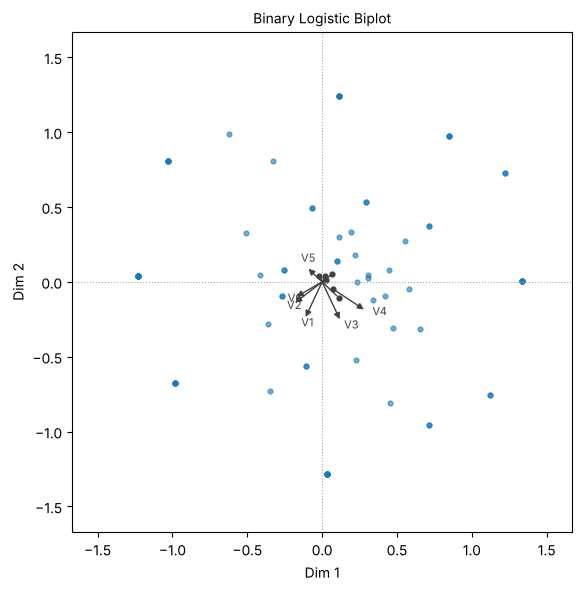

In [7]:
n = 80
Z = rng.normal(size=(n, 2))
Xc = Z @ rng.normal(size=(2, 4)) + rng.normal(0, 0.5, (n, 4))          # explicativas continuas
Yb = (rng.random((n, 6)) < 1 / (1 + np.exp(-(Z @ rng.normal(0, 1.5, (2, 6)))))).astype(float)
lb = bp.binary_logistic_biplot(Yb, penalization=0.5)
print(lb)
lb.plot(); plt.show()

       b0     b1     b2  Deviance  p-value  % correct  McFadden R2
V1  0.071 -0.337 -0.661    20.541      0.0      71.25        0.185
V2  0.514 -1.552 -1.911    69.551      0.0      87.50        0.615
V3  0.048  0.700 -0.670    27.728      0.0      73.75        0.250
V4 -0.278  1.904 -1.409    67.225      0.0      88.75        0.604
V5  0.539 -1.428  1.054    54.301      0.0      82.50        0.488
V6  0.104 -1.013 -0.833    40.617      0.0      78.75        0.366


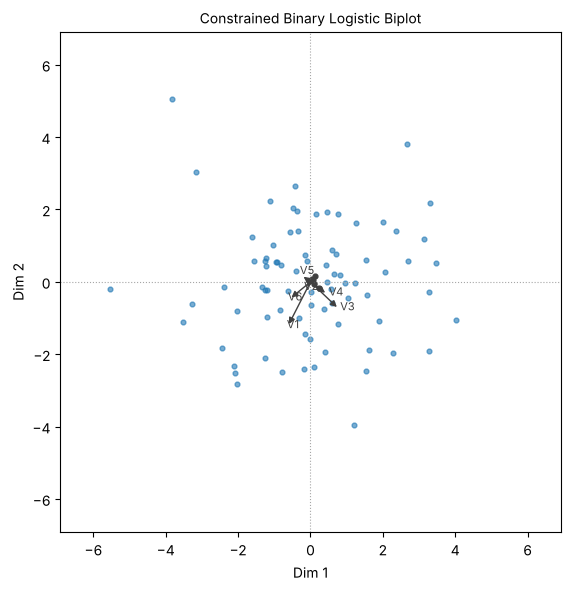

In [8]:
cbl = bp.constrained_logistic_biplot(Yb, Xc, penalization=0.1)
print(cbl.columns.round(3))
cbl.plot(); plt.show()

    Deviance  p-value    PCC
V1   171.715    0.000  0.538
V2   185.753    0.000  0.500
V3   166.229    0.000  0.562
V4   218.003    0.286  0.325
V5   219.638    0.483  0.338


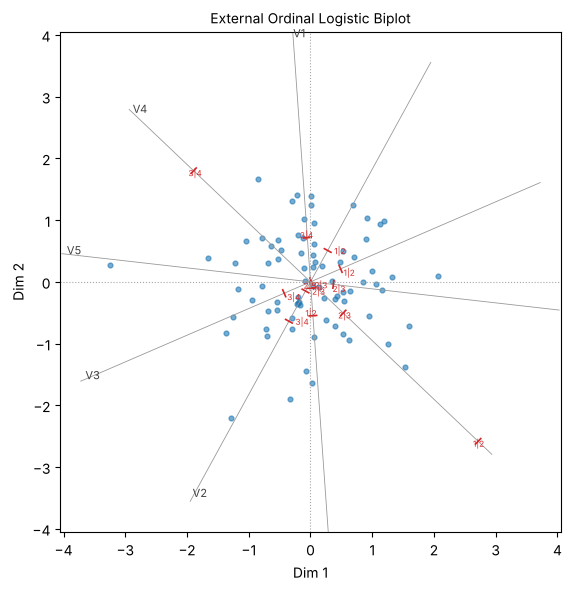

In [9]:
lat = Z @ rng.normal(0, 1.3, (2, 5)) + rng.logistic(size=(n, 5))
Yo = np.digitize(lat, [-1.2, 0, 1.2]) + 1                                # ordinales 1..4
co = bp.constrained_ordinal_logistic_biplot(Yo, Xc)
print(co.column_parameters["fit"][["Deviance", "p-value", "PCC"]].round(3))
eo = bp.external_ordinal_logistic_biplot(bp.pca_biplot(Xc), Yo)          # sobre el PCA de Xc
eo.plot(); plt.show()

## 4. Tablas múltiples: STATIS y biplot dinámico

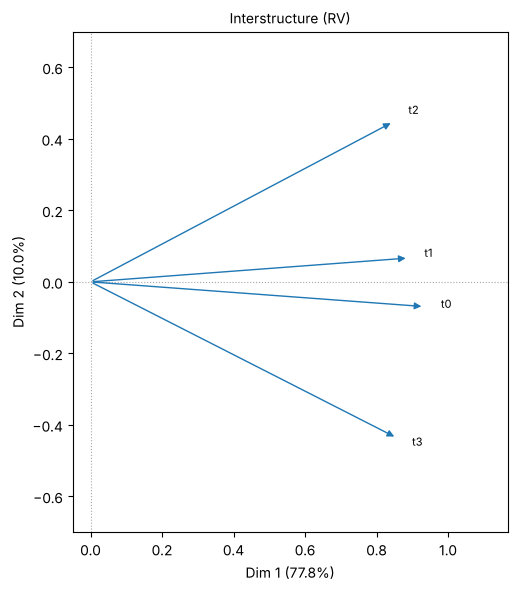

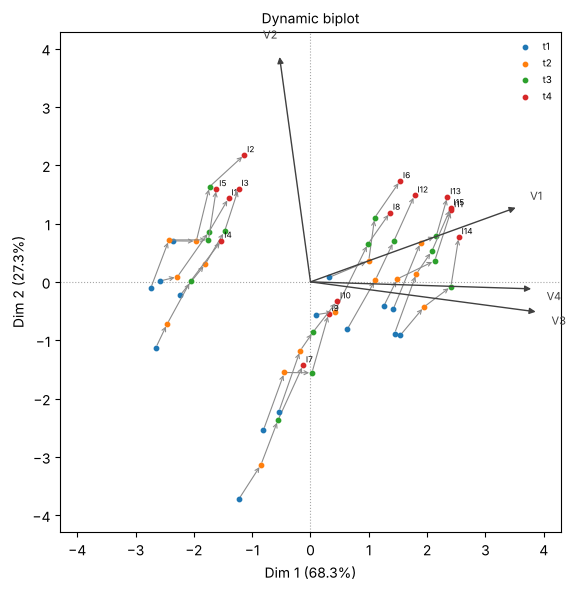

In [10]:
tablas = {f"t{k}": X.to_numpy()[::5] + rng.normal(0, 0.3 + 0.2 * k, (30, 4)) for k in range(4)}
st = bp.statis(tablas)
bp.plot_statis(st, "interstructure"); plt.show()
ocas = [X.to_numpy()[::10] + 0.25 * t + rng.normal(0, 0.1, (15, 4)) for t in range(4)]
bp.plot_dynamic(bp.dynamic_biplot(ocas, alpha=2)); plt.show()

## 5. Interacción genotipo × ambiente: GGE y AMMI

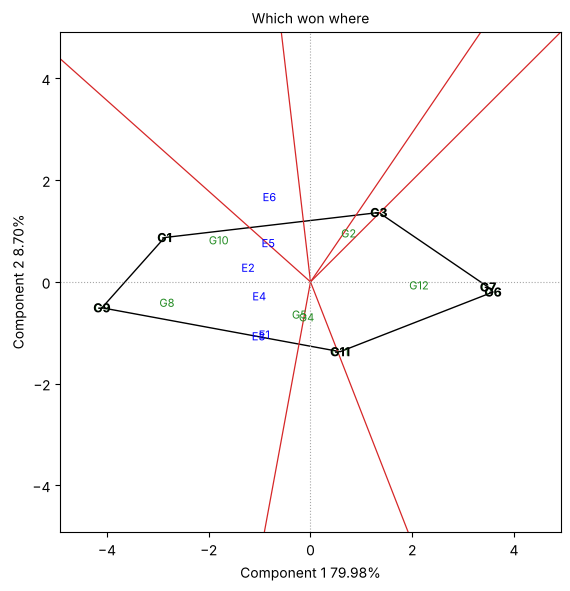

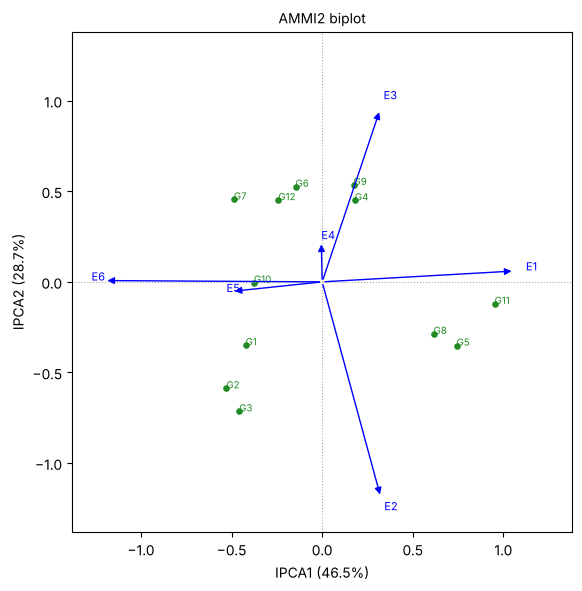

In [11]:
G, E = 12, 6
gxe = pd.DataFrame(5 + rng.normal(size=(G, 1)) + rng.normal(size=(1, E)) + rng.normal(0, 0.6, (G, E)),
                   index=[f"G{i+1}" for i in range(G)], columns=[f"E{j+1}" for j in range(E)])
gm = bp.gge_model(gxe, centering="tester", scaling="none", svp="row")
bp.plot_gge(gm, "which_won_where"); plt.show()
largo = gxe.stack().reset_index(); largo.columns = ["gen", "env", "y"]
largo = pd.concat([largo.assign(rep=r, y=largo["y"] + rng.normal(0, 0.3, len(largo))) for r in (1, 2)])
am = bp.ammi(largo["env"].tolist(), largo["gen"].tolist(), largo["rep"].tolist(), largo["y"].tolist())
bp.plot_ammi(am, "AMMI2"); plt.show()

## 6. Correspondencias: CA, MCA, CCA y RDA

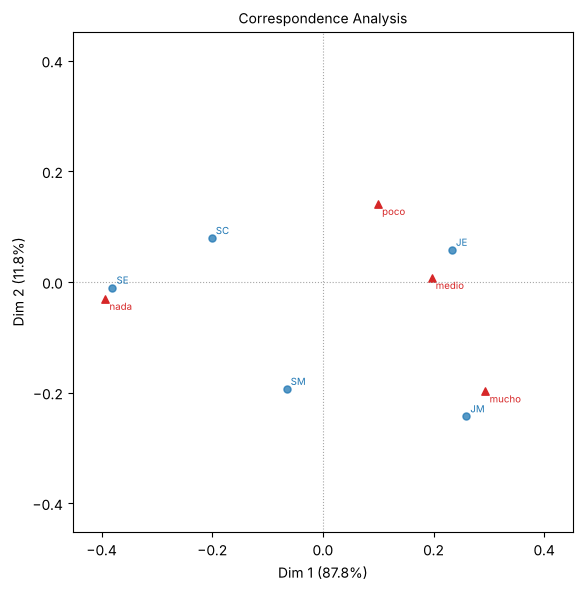

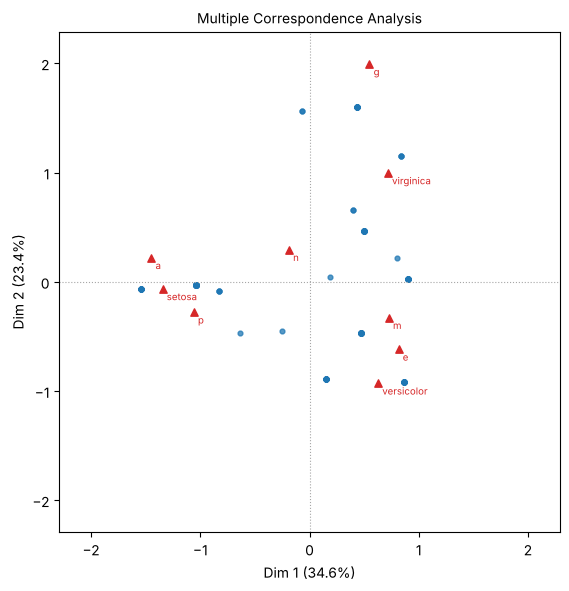

In [12]:
fum = pd.DataFrame([[4, 2, 3, 2], [4, 3, 7, 4], [25, 10, 12, 4], [18, 24, 33, 13], [10, 6, 7, 2]],
                   index=["SM", "JM", "SE", "JE", "SC"], columns=["nada", "poco", "medio", "mucho"])
bp.ca(fum).plot(); plt.show()
cualit = pd.DataFrame({"tamaño": pd.cut(iris["Sepal.Length"], 3, labels=["p", "m", "g"]).astype(str),
                       "ancho": pd.cut(iris["Sepal.Width"], 3, labels=["e", "n", "a"]).astype(str),
                       "especie": especie.astype(str)})
bp.plot_ordination(bp.mca(cualit), col_labels=True); plt.show()

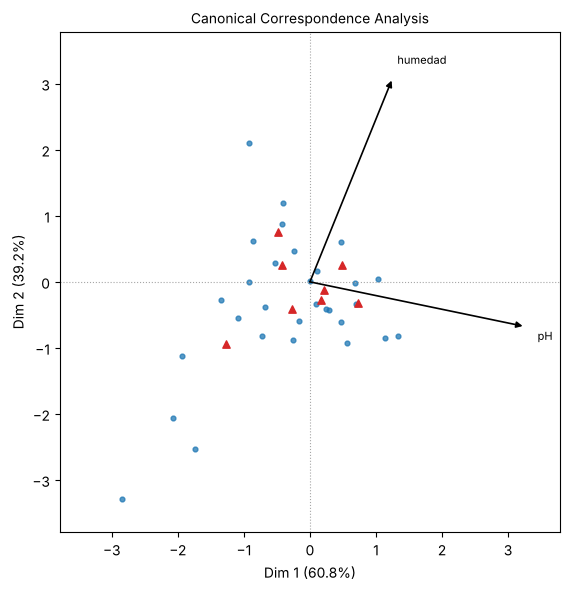

In [13]:
especies = rng.poisson(np.exp(1 + Z[:30] @ rng.normal(0, 0.8, (2, 8))))       # abundancias
ambiente = pd.DataFrame(Z[:30] + rng.normal(0, 0.3, (30, 2)), columns=["pH", "humedad"])
bp.plot_ordination(bp.cca(especies, ambiente), col_labels=False); plt.show()

## 7. Distancias: coordenadas principales, MDS y bootstrap

`bootstrap_pcoa` y `bootstrap_mds` remuestrean los residuos entre las distancias observadas y las
ajustadas, reajustan la ordenación y alinean cada réplica por Procrustes: la nube de cada
individuo indica la estabilidad de su posición.

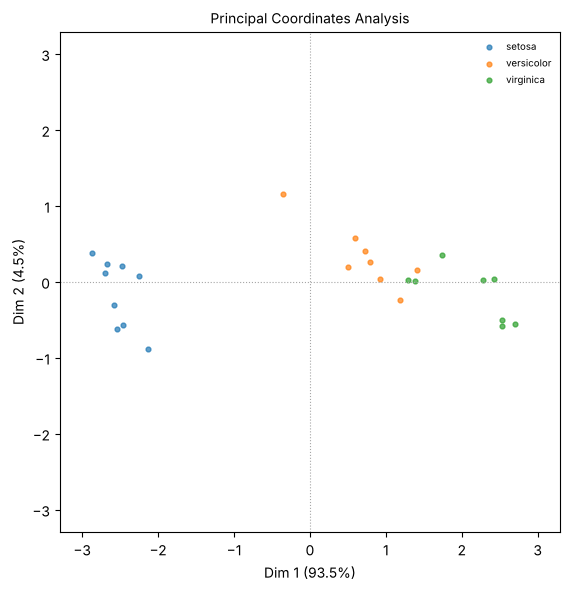

stress-1: 0.0196


In [14]:
D = bp.continuous_distances(X.to_numpy()[::6])
pc = bp.pcoa(D)
bp.plot_ordination(pc, groups=especie[::6].to_numpy()); plt.show()
md_ = bp.mds(D, type="ordinal")
print("stress-1:", round(md_.stress, 4))

    sd Dim 1  sd Dim 2
I1  0.031064  0.143087
I2  0.034205  0.158055
I3  0.032692  0.159502
I4  0.029339  0.138017
I5  0.029344  0.136414


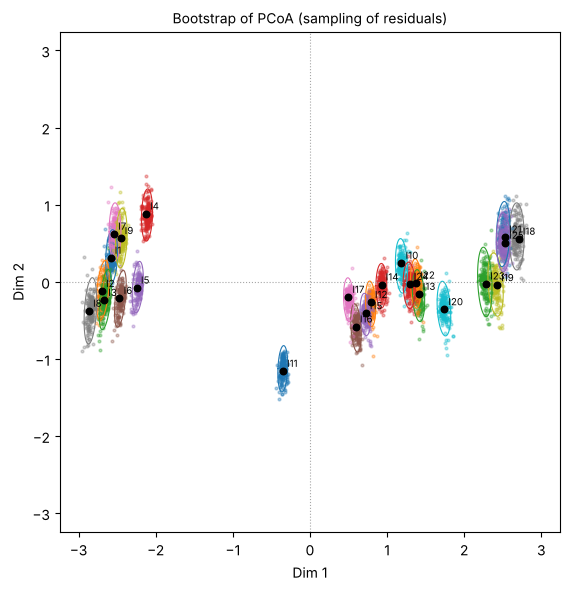

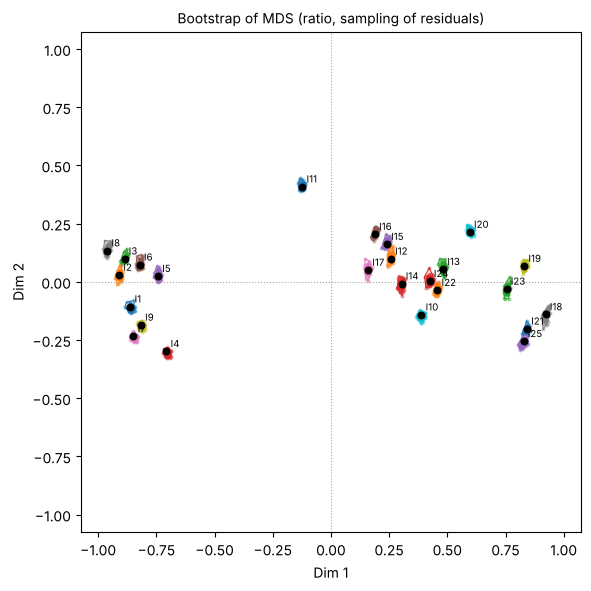

In [15]:
bt = bp.bootstrap_pcoa(D, nB=200, seed=1)
print(bt.summary().head())
bt.plot(); plt.show()
bm = bp.bootstrap_mds(D, nB=100, seed=1)
bm.plot(kind="hull"); plt.show()

## 8. Modelos factoriales y PLS

Incluye el biplot factorial con rotaciones, NIPALS con datos faltantes, la regresión PLS y su
biplot, y la PLS con respuestas binarias: **PLSR1Bin** (una respuesta binaria y predictores
continuos) y **BinaryPLSR** (predictores y respuestas binarios).

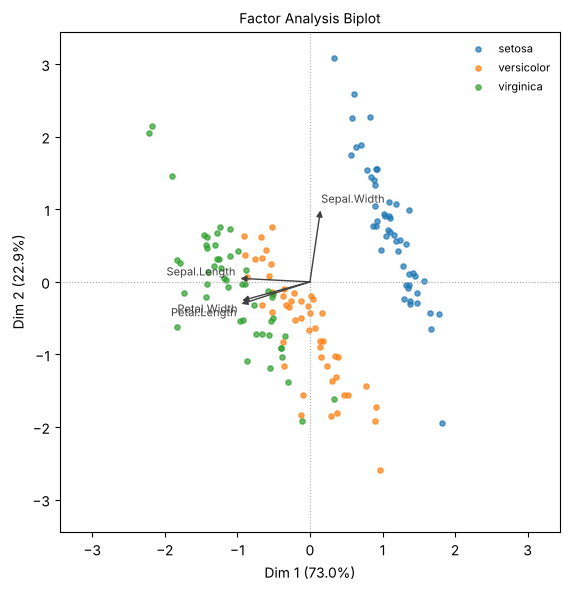

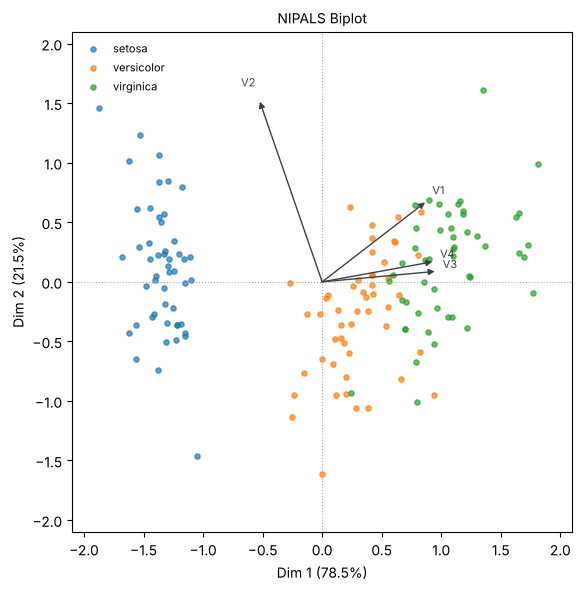

In [16]:
fa = bp.fa_biplot(X, 2, "varimax"); bp.plot_biplot(fa, groups=especie); plt.show()
Xm = X.to_numpy().copy(); Xm[rng.random(Xm.shape) < 0.1] = np.nan
bp.plot_biplot(bp.nipals_biplot(Xm, 2), groups=especie); plt.show()

              Comp. 1  Comp. 2
Sepal.Length    0.249   -0.356
Sepal.Width    -0.036   -0.198
Petal.Length    0.714    0.567
Petal.Width     0.653    0.716
% bien clasificados: 98.0


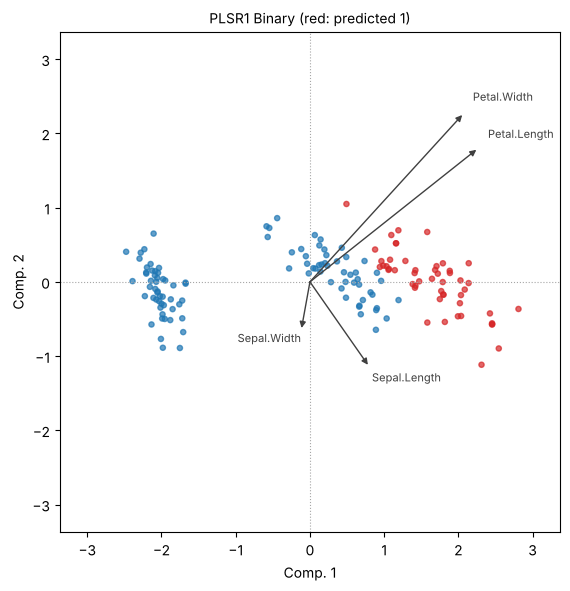

In [17]:
y = (iris["Species"] == "virginica").astype(float).to_numpy()
p1 = bp.plsr1_bin(y, X, S=2)
print(p1["weights"].round(3))
print("% bien clasificados:", round(100 * p1["fit"]["percent_correct"], 1))
bp.plot_plsbin(p1); plt.show()

% de aciertos en Y: 67.1


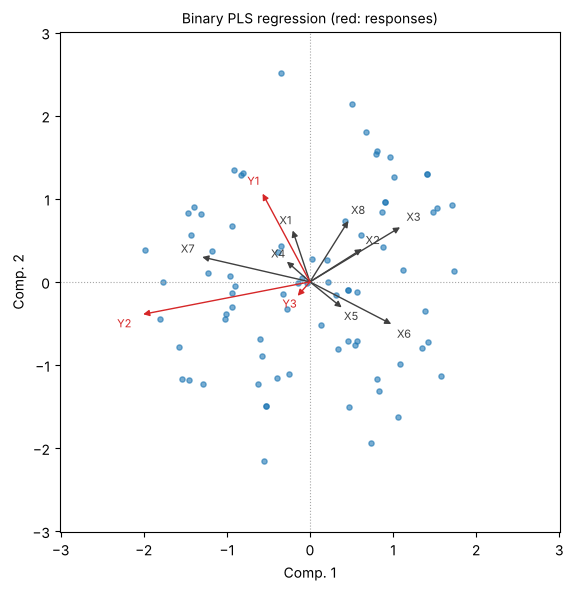

In [18]:
Xb = (rng.random((n, 8)) < 1 / (1 + np.exp(-(Z @ rng.normal(0, 1.5, (2, 8)))))).astype(float)
bpls = bp.binary_plsr(Yb[:, :3], Xb, S=2, seed=0)        # la semilla reproduce la de R
print("% de aciertos en Y:", round(100 * bpls["percent_correct"], 1))
bp.plot_plsbin(bpls); plt.show()

## 9. Otros métodos

Unfolding métrico (SMACOF), DISTATIS, agrupamiento con PCA disjunto (CDPCA) y el biplot de
frecuencias logarítmicas, que aproxima log(N + 1) por mínimos cuadrados alternados ponderados.

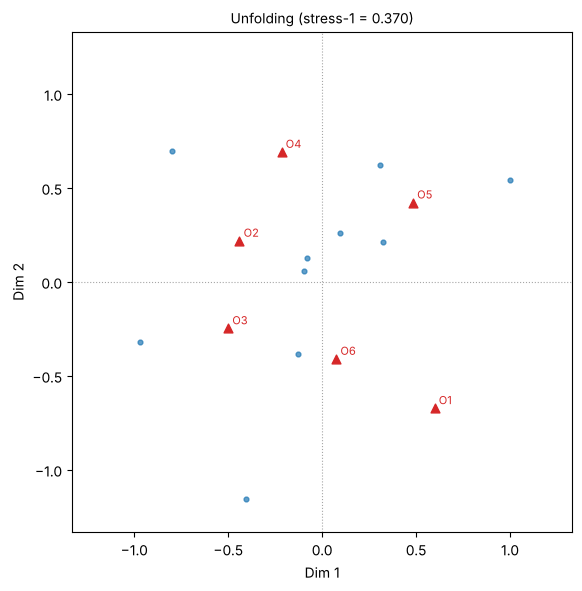

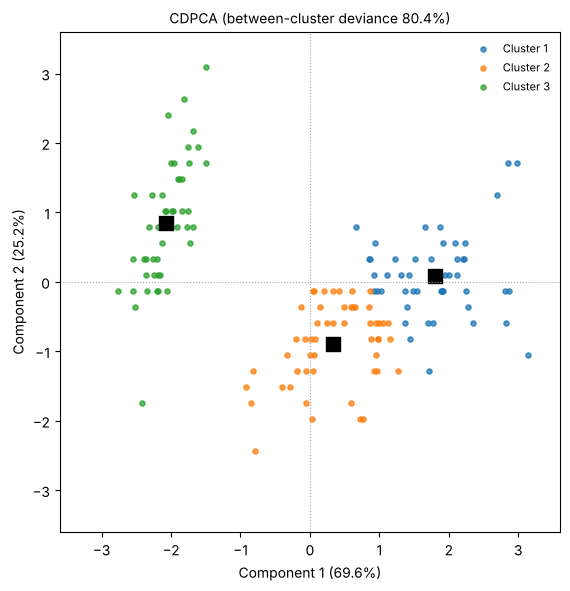

bondad de ajuste: 0.862


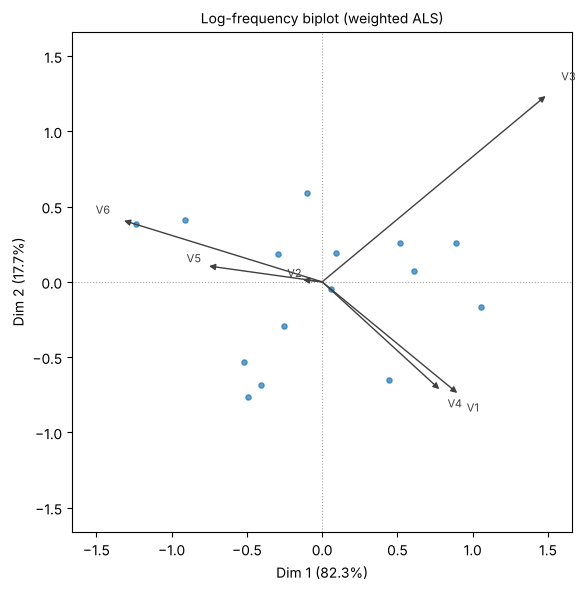

In [19]:
pref = np.abs(rng.normal(size=(10, 6))) * 3
bp.plot_unfolding(bp.unfolding(pref)); plt.show()
cd = bp.cdpca(X.to_numpy(), 3, 2, nstart=10, seed=1)
bp.plot_cdpca(cd); plt.show()
conteos = rng.poisson(np.exp(1 + Z[:15] @ rng.normal(0, 0.5, (2, 6))))
lf = bp.log_frequency_biplot(conteos, seed=11)
print("bondad de ajuste:", round(lf.goodness_of_fit, 3))
lf.plot(); plt.show()

## Reproducibilidad frente a R

Los métodos que parten de números aleatorios aceptan `seed`; con ella usan el generador de R
(`bp.RRNG`), de modo que `seed=11` da el mismo resultado que `set.seed(11)` en R. Las pruebas
del paquete (`tests/`) comparan cada método con su versión de R; la tabla de diferencias
máximas está en el README.